# Financial Sentiment Analysis with Deep Learning
### A BiLSTM trained from scratch: baseline → step-by-step improvements

This project classifies financial news sentences as **positive**, **negative** or **neutral** using a deep-learning model (embedding layer + bidirectional LSTM) trained **from scratch** — no pretrained weights or embeddings.

**Project steps**

| # | Step | What happens |
|---|------|--------------|
| 1 | Introduction | Problem statement and goal |
| 2 | Setup | Libraries, reproducibility |
| 3 | Dataset | Load the Kaggle *Sentiment Analysis for Financial News* data |
| 4 | Exploratory Data Analysis | Class balance, sentence lengths, vocabulary, data-quality issues |
| 5 | Preprocessing | Cleaning, tokenization, stratified train/validation/test split |
| 6 | Model & training code | BiLSTM architecture, training loop, metrics |
| 7 | **Model 1 – Baseline** | A first working model and its weaknesses |
| 8 | **Model 2 – Better representation** | Number normalisation + max/mean pooling |
| 9 | **Model 3 – Regularisation** | Dropout and weight decay against overfitting |
| 10 | **Model 4 – Tuning (final)** | Stronger weight decay, smaller batches |
| 11 | Results comparison | Metrics table, charts, confusion matrices |
| 12 | Robustness check (optional) | Repeat every model with several random seeds |
| 13 | Error analysis | What the final model still gets wrong |
| 14 | Conclusions | Findings, limitations and next steps |

**Running it:** works in Google Colab or any local Jupyter. A GPU is optional (in Colab: *Runtime → Change runtime type → T4 GPU*); on CPU the whole notebook takes a few minutes longer. Use *Runtime → Run all*.

## 1. Introduction

Financial sentiment analysis identifies the sentiment expressed in financial news, reports and other financial text. That sentiment can influence investment decisions, market analysis and how a company's performance is perceived.

**Problem statement.** Financial news is full of domain-specific terminology and subtle phrasing: *"operating loss narrowed"* is good news, while *"sales increased less than expected"* is not. General-purpose sentiment techniques struggle with these nuances. The goal here is to build a deep-learning classifier for financial news sentences and **improve it systematically**, measuring every change with the same data split and the same metrics:

* **Accuracy** – share of correct predictions.
* **Precision, recall and F1 per class.**
* **Macro-F1** – the unweighted average F1 over the three classes. This is our **main metric** because the classes are imbalanced (see EDA): a model that always answers *neutral* gets high accuracy but a poor macro-F1.
* **Confusion matrix** – which classes get confused with which.

## 2. Setup

Imports libraries, fixes random seeds so results are repeatable.

In [ ]:
import importlib.util
import subprocess
import sys

In [ ]:
import copy
import csv
import io
import random
import re
import time
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence, pad_sequence
from torch.utils.data import DataLoader, Dataset
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, classification_report, confusion_matrix, f1_score,
)

SEED = 42

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
set_seed(SEED)

pd.set_option("display.max_colwidth", 140)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
CLASS_COLORS = {"negative": "#d62728", "neutral": "#8c8c8c", "positive": "#2ca02c"}

## 3. Dataset

We use the public **[Sentiment Analysis for Financial News](https://www.kaggle.com/datasets/ankurzing/sentiment-analysis-for-financial-news)** dataset from Kaggle (based on the *Financial PhraseBank*, Malo et al. 2014). The file `all-data.csv` holds ~4,800 English financial news sentences, each labelled by finance-literate annotators.

In [ ]:
DATA_FILE = "all-data.csv"
SEARCH_PATHS = [
    Path(DATA_FILE), Path("dataset") / DATA_FILE,
    Path("/content") / DATA_FILE, Path("/content/drive/MyDrive") / DATA_FILE,
]
data_path = next((path for path in SEARCH_PATHS if path.exists()), None)
if data_path is None:
    try:
        from google.colab import files
    except ImportError:
        raise FileNotFoundError(f"Place {DATA_FILE} next to this notebook or in a dataset/ folder.")
    print(f"Upload {DATA_FILE} (Kaggle: Sentiment Analysis for Financial News)")
    uploaded = files.upload()
    data_path = Path(next(iter(uploaded)))
print("Using:", data_path.resolve())


def load_financial_news(path):
    raw = Path(path).read_bytes()
    try:
        text = raw.decode("utf-8")
    except UnicodeDecodeError:
        text = raw.decode("latin-1")  # the Kaggle file is Latin-1 encoded
    records = list(csv.reader(io.StringIO(text, newline="")))
    if records and records[0][0].strip().lower() in ("label", "sentiment"):
        records = records[1:]  # tolerate copies of the file that have a header
    rows = [(r[1].strip(), r[0].strip().lower()) for r in records if len(r) == 2]
    if len(rows) != len(records):
        print(f"Skipped {len(records) - len(rows)} malformed lines.")
    return pd.DataFrame(rows, columns=["text", "label"])


df = load_financial_news(data_path)
print(f"{len(df):,} sentences loaded")
df.head()

Using: /content/all-data.csv
4,846 sentences loaded


,text,label
0,"According to Gran , the company has no plans to move all production to Russia , although that is where the company is growing .",neutral
1,"Technopolis plans to develop in stages an area of no less than 100,000 square meters in order to host companies working in computer tech...",neutral
2,The international electronic industry company Elcoteq has laid off tens of employees from its Tallinn facility ; contrary to earlier lay...,negative
3,With the new production plant the company would increase its capacity to meet the expected increase in demand and would improve the use ...,positive
4,"According to the company 's updated strategy for the years 2009-2012 , Basware targets a long-term net sales growth in the range of 20 %...",positive


## 4. Exploratory Data Analysis (EDA)

### 4.1 Class distribution

,sentences,share (%)
label,,
neutral,2879,59.4
positive,1363,28.1
negative,604,12.5


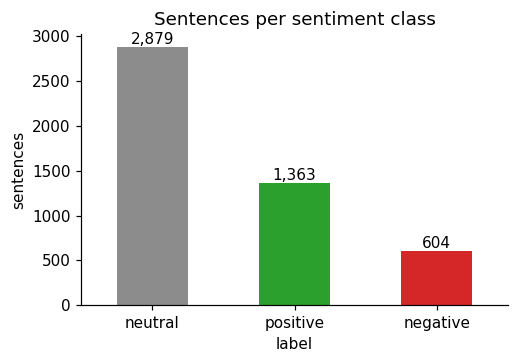

In [ ]:
counts = df["label"].value_counts()
display(pd.DataFrame({"sentences": counts, "share (%)": (100 * counts / len(df)).round(1)}))

ax = counts.plot.bar(color=[CLASS_COLORS[label] for label in counts.index], figsize=(5, 3.2), rot=0)
ax.set_title("Sentences per sentiment class")
ax.set_ylabel("sentences")
for patch, value in zip(ax.patches, counts):
    ax.annotate(f"{value:,}", (patch.get_x() + patch.get_width() / 2, value), ha="center", va="bottom")
plt.show()

The dataset is **imbalanced**: roughly 6 in 10 sentences are neutral and only about 1 in 8 is negative. Consequences for the project:
* accuracy alone is misleading → we select models by **macro-F1**;
* every split must keep the same class proportions → **stratified** splitting.

### 4.2 Sentence length

The model works on **tokens** (words and punctuation marks). We define the tokenizer now so the EDA counts exactly what the model will see.

['operating', 'profit', 'rose', 'to', 'eur', '13', '.', '1', 'mn', 'from', 'eur', '8', '.', '7', 'mn', '.']
['operating', 'profit', 'rose', 'to', 'eur', '<num>', '.', '<num>', 'mn', 'from', 'eur', '<num>', '.', '<num>', 'mn', '.']


,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
negative,604.0,27.1,11.4,5.0,19.0,25.0,34.0,61.0
neutral,2879.0,23.9,11.1,2.0,16.0,22.0,30.0,111.0
positive,1363.0,27.2,11.2,5.0,18.0,25.0,35.0,63.0


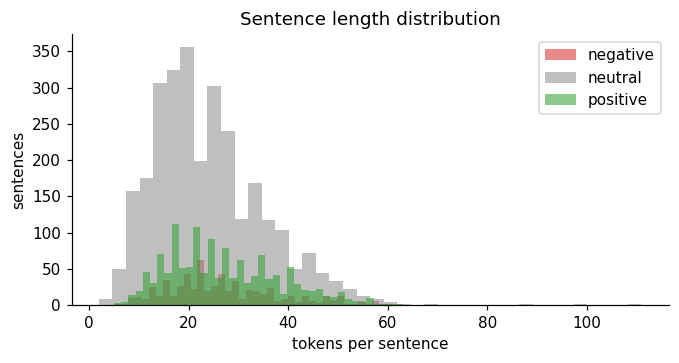

In [ ]:
TOKEN_PATTERN = re.compile(r"\w+(?:['’]\w+)*|[^\w\s]")


def tokenize(text, normalize_numbers=False):
    """Lower-case word/punctuation tokens; optionally map every token containing a digit to <num>."""
    tokens = TOKEN_PATTERN.findall(text.casefold())
    if normalize_numbers:
        tokens = ["<num>" if any(ch.isdigit() for ch in tok) else tok for tok in tokens]
    return tokens


print(tokenize("Operating profit rose to EUR 13.1 mn from EUR 8.7 mn ."))
print(tokenize("Operating profit rose to EUR 13.1 mn from EUR 8.7 mn .", normalize_numbers=True))

df["n_tokens"] = df["text"].map(lambda text: len(tokenize(text)))
display(df.groupby("label")["n_tokens"].describe().round(1))

fig, ax = plt.subplots(figsize=(7, 3.2))
for label in ["negative", "neutral", "positive"]:
    ax.hist(df.loc[df.label == label, "n_tokens"], bins=40, alpha=0.55, label=label, color=CLASS_COLORS[label])
ax.set_xlabel("tokens per sentence")
ax.set_ylabel("sentences")
ax.set_title("Sentence length distribution")
ax.legend()
plt.show()

Sentences are short (median ≈ 23 tokens, longest ≈ 110), so a recurrent model can read each sentence completely; we cap inputs at 128 tokens, which truncates nothing.

### 4.3 Vocabulary and numbers

Which words are typical for each class, and how often do numbers appear?

In [ ]:
STOPWORDS = set("""the a an of to in and for on is was by with as at from its it that be has have will are
this which or said also been their after than had were but not into per our we he she they""".split())

def top_words(texts, n=15):
    counter = Counter(
        tok for text in texts for tok in tokenize(text)
        if tok.isalpha() and len(tok) > 2 and tok not in STOPWORDS
    )
    return [f"{word} ({count})" for word, count in counter.most_common(n)]

display(pd.DataFrame({label: top_words(df.loc[df.label == label, "text"]) for label in ["negative", "neutral", "positive"]}))

has_number = df["text"].str.contains(r"\d")
print(f"Sentences containing a number: {has_number.mean():.0%}")
display((100 * has_number.groupby(df["label"]).mean()).round(1).rename("% with a number").to_frame())
all_tokens = [tok for text in df["text"] for tok in tokenize(text)]
numeric_types = {tok for tok in all_tokens if any(ch.isdigit() for ch in tok)}
print(f"Distinct token types: {len(set(all_tokens)):,}, of which numeric: {len(numeric_types):,}")

,negative,neutral,positive
0,eur (325),company (510),eur (450)
1,profit (156),eur (243),company (241)
2,net (104),finland (228),year (212)
3,finnish (102),finnish (220),finnish (202)
4,company (100),business (195),net (196)
5,year (100),million (192),sales (192)
6,sales (98),group (190),profit (192)
7,operating (97),new (189),million (170)
8,period (90),sales (165),period (139)
9,quarter (89),shares (163),mln (128)


Sentences containing a number: 53%


,% with a number
label,
negative,75.3
neutral,46.6
positive,57.7


Distinct token types: 10,135, of which numeric: 1,092


Positive and negative sentences are dominated by words like *profit, sales, increased, decreased, loss* – the **direction** words carry the sentiment. About half of all sentences contain numbers (more often the positive and negative ones), and roughly one in nine distinct tokens is numeric. Most of these number tokens are rare, so the model cannot learn much from any individual value. (The tokenizer splits `13.1` into `13`, `.`, `1`.) This motivates *number normalisation* later (Model 2).

### 4.4 Data quality: duplicates and conflicting labels

In [ ]:
keys = df["text"].map(lambda text: tuple(tokenize(text)))
labels_per_text = df.groupby(keys)["label"].nunique()
conflicting = set(labels_per_text[labels_per_text > 1].index)
is_conflict = keys.map(lambda key: key in conflicting)
is_duplicate = keys.duplicated(keep="first") & ~is_conflict

print(f"Exact duplicate sentences (same label): {int(is_duplicate.sum())}")
print(f"Sentences appearing with *different* labels: {len(conflicting)} texts, {int(is_conflict.sum())} rows")
display(df.loc[is_conflict, ["text", "label"]].sort_values("text"))

Exact duplicate sentences (same label): 6
Sentences appearing with *different* labels: 2 texts, 4 rows


,text,label
78,TELECOMWORLDWIRE-7 April 2006-TJ Group Plc sells stake in Morning Digital Design Oy Finnish IT company TJ Group Plc said on Friday 7 Apr...,neutral
79,TELECOMWORLDWIRE-7 April 2006-TJ Group Plc sells stake in Morning Digital Design Oy Finnish IT company TJ Group Plc said on Friday 7 Apr...,positive
788,The Group 's business is balanced by its broad portfolio of sports and presence in all major markets .,positive
789,The Group 's business is balanced by its broad portfolio of sports and presence in all major markets .,neutral


**EDA summary**
* ~4,850 short sentences, 3 classes, strongly imbalanced towards *neutral*.
* Many numbers; sentiment comes mostly from direction words (*rose, fell, increased, loss*).
* A handful of duplicates and a few texts with contradictory labels – both must be removed, otherwise the same sentence could appear in training **and** test (leakage) or teach the model contradictions.

## 5. Preprocessing

1. Remove texts with conflicting labels and drop duplicates.
2. Split **stratified** into 70 % train / 15 % validation / 15 % test. The split is fixed (seed 42) and **identical for every model**, so comparisons are fair.
   * **train** – the model learns from it;
   * **validation** – used for early stopping and for *choosing between models*;
   * **test** – only for reporting; never used to make decisions.
3. Build the vocabulary from the **training set only** (words seen only in validation/test map to `<unk>`, as they would for genuinely new text).

In [ ]:
clean = df.loc[~is_conflict].copy()
clean = clean.loc[~clean["text"].map(lambda text: tuple(tokenize(text))).duplicated(keep="first")]
rows = list(zip(clean["text"], clean["label"]))
print(f"{len(df):,} raw rows → {len(rows):,} clean, unique sentences")


def stratified_split(rows, validation_fraction=0.15, test_fraction=0.15, seed=SEED):
    by_label = defaultdict(list)
    for row in rows:
        by_label[row[1]].append(row)
    rng = random.Random(seed)
    train, validation, test = [], [], []
    for label, examples in sorted(by_label.items()):
        examples = examples[:]
        rng.shuffle(examples)
        n_val = max(1, int(len(examples) * validation_fraction))
        n_test = max(1, int(len(examples) * test_fraction))
        validation += examples[:n_val]
        test += examples[n_val:n_val + n_test]
        train += examples[n_val + n_test:]
    for split in (train, validation, test):
        rng.shuffle(split)
    return train, validation, test


train_rows, val_rows, test_rows = stratified_split(rows)
SPLITS = {"train": train_rows, "validation": val_rows, "test": test_rows}
LABELS = sorted({label for _, label in rows})
LABEL_IDS = {label: i for i, label in enumerate(LABELS)}

split_table = pd.DataFrame({name: Counter(label for _, label in split) for name, split in SPLITS.items()}).loc[LABELS]
split_table.loc["total"] = split_table.sum()
display(split_table)

4,846 raw rows → 4,836 clean, unique sentences


,train,validation,test
negative,424,90,90
neutral,2011,430,430
positive,953,204,204
total,3388,724,724


**Turning text into tensors.** Each sentence becomes a sequence of integer token ids. Sentences in a batch have different lengths, so they are padded with id 0 (`<pad>`); the model is told each real length so padding never influences the result.

In [ ]:
def build_vocab(train_rows, normalize_numbers=False, min_frequency=1, max_vocab=30000):
    counts = Counter(tok for text, _ in train_rows for tok in tokenize(text, normalize_numbers))
    vocab = {"<pad>": 0, "<unk>": 1}
    for token, count in sorted(counts.items(), key=lambda item: (-item[1], item[0])):
        if count < min_frequency or len(vocab) >= max_vocab:
            break
        vocab.setdefault(token, len(vocab))
    return vocab


def encode(text, vocab, max_length=128, normalize_numbers=False):
    ids = [vocab.get(tok, 1) for tok in tokenize(text, normalize_numbers)[:max_length]]
    return torch.tensor(ids or [1], dtype=torch.long)


class TextDataset(Dataset):
    def __init__(self, rows, vocab, max_length, normalize_numbers):
        self.examples = [(encode(text, vocab, max_length, normalize_numbers), LABEL_IDS[label]) for text, label in rows]

    def __len__(self):
        return len(self.examples)

    def __getitem__(self, index):
        return self.examples[index]


def collate(batch):
    sequences, labels = zip(*batch)
    lengths = torch.tensor([len(seq) for seq in sequences], dtype=torch.long)
    return pad_sequence(sequences, batch_first=True, padding_value=0), lengths, torch.tensor(labels)


example_vocab = build_vocab(train_rows)
print(f"Vocabulary size (train only): {len(example_vocab):,}")
print(train_rows[0][0])
print(encode(train_rows[0][0], example_vocab))

Vocabulary size (train only): 8,317
The company expects meat purchases to remain at about 8mn kilos in 2011 .
tensor([   3,   17,  262,  606, 1389,    8,  578,   33,   86, 1913, 2552,    6,
         168,    2])


## 6. Model and training code

**Architecture** (all weights randomly initialised and learned from our ~3,400 training sentences):

```
token ids ──► Embedding (128-d) ──► Bidirectional LSTM (128 units each way) ──► sentence vector ──► Dropout ──► Linear ──► 3 class scores
```

* The **embedding** layer learns a vector for every word.
* The **bidirectional LSTM** reads the sentence left-to-right and right-to-left, so each position sees its full context (*"profit **fell**"* vs *"loss **fell**"*).
* The **sentence vector** is built in one of two ways (`pooling`):
  * `last` – the final hidden states of both directions (baseline);
  * `max_mean` – max-pooling **and** mean-pooling over the LSTM outputs at every word (introduced in Model 2).

The training loop uses cross-entropy loss, the Adam(W) optimiser, gradient clipping and **early stopping**: after each epoch we measure validation macro-F1, keep the best weights, and stop when there has been no improvement for `patience` epochs.

In [ ]:
class SentimentModel(nn.Module):
    def __init__(self, vocab_size, num_classes, embedding_dim=128, hidden_dim=128,
                 dropout=0.3, embedding_dropout=0.0, pooling="last"):
        super().__init__()
        self.pooling = pooling
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)
        self.embedding_dropout = nn.Dropout(embedding_dropout)
        self.encoder = nn.LSTM(embedding_dim, hidden_dim, batch_first=True, bidirectional=True)
        self.dropout = nn.Dropout(dropout)
        features = (4 if pooling == "max_mean" else 2) * hidden_dim
        self.classifier = nn.Linear(features, num_classes)

    def forward(self, token_ids, lengths):
        embedded = self.embedding_dropout(self.embedding(token_ids))
        packed = pack_padded_sequence(embedded, lengths.cpu(), batch_first=True, enforce_sorted=False)
        outputs, (hidden, _) = self.encoder(packed)
        if self.pooling == "last":
            features = torch.cat((hidden[-2], hidden[-1]), dim=1)
        else:
            outputs, _ = pad_packed_sequence(outputs, batch_first=True)
            lengths = lengths.to(outputs.device)
            mask = (torch.arange(outputs.size(1), device=outputs.device)[None, :] < lengths[:, None]).unsqueeze(2)
            maximum = outputs.masked_fill(~mask, float("-inf")).amax(dim=1)
            mean = outputs.masked_fill(~mask, 0).sum(dim=1) / lengths[:, None]
            features = torch.cat((maximum, mean), dim=1)
        return self.classifier(self.dropout(features))

In [ ]:
BASE_CONFIG = dict(
    normalize_numbers=False, pooling="last", embedding_dim=128, hidden_dim=128,
    dropout=0.3, embedding_dropout=0.0, weight_decay=0.0, learning_rate=1e-3,
    batch_size=32, max_length=128, epochs=30, patience=5,
)
RESULTS = {}


@torch.inference_mode()
def evaluate(model, loader):
    model.eval()
    criterion = nn.CrossEntropyLoss(reduction="sum")
    loss, probs, targets = 0.0, [], []
    for tokens, lengths, labels in loader:
        logits = model(tokens.to(DEVICE), lengths)
        loss += criterion(logits, labels.to(DEVICE)).item()
        probs.append(logits.softmax(dim=1).cpu())
        targets.append(labels)
    probs, targets = torch.cat(probs).numpy(), torch.cat(targets).numpy()
    preds = probs.argmax(axis=1)
    return {
        "loss": loss / len(targets), "accuracy": accuracy_score(targets, preds),
        "macro_f1": f1_score(targets, preds, average="macro"),
        "class_f1": dict(zip(LABELS, f1_score(targets, preds, average=None, labels=range(len(LABELS))))),
        "cm": confusion_matrix(targets, preds, labels=range(len(LABELS))),
        "preds": preds, "targets": targets, "probs": probs,
    }


def run_experiment(name, config, seed=SEED, verbose=True, record=True):
    cfg = {**BASE_CONFIG, **config}
    set_seed(seed)
    vocab = build_vocab(train_rows, cfg["normalize_numbers"])
    generator = torch.Generator().manual_seed(seed)
    loaders = {
        split: DataLoader(TextDataset(split_rows, vocab, cfg["max_length"], cfg["normalize_numbers"]),
                          batch_size=cfg["batch_size"], shuffle=(split == "train"), collate_fn=collate,
                          generator=generator if split == "train" else None)
        for split, split_rows in SPLITS.items()
    }
    model = SentimentModel(len(vocab), len(LABELS), cfg["embedding_dim"], cfg["hidden_dim"],
                           cfg["dropout"], cfg["embedding_dropout"], cfg["pooling"]).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=cfg["learning_rate"], weight_decay=cfg["weight_decay"])
    criterion = nn.CrossEntropyLoss()
    if verbose:
        print(f"{name}: {sum(p.numel() for p in model.parameters()):,} parameters, vocabulary {len(vocab):,}")

    history, best, stale, started = [], {"f1": -1.0}, 0, time.time()
    for epoch in range(1, cfg["epochs"] + 1):
        model.train()
        train_loss = 0.0
        for tokens, lengths, labels in loaders["train"]:
            tokens, labels = tokens.to(DEVICE), labels.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            loss = criterion(model(tokens, lengths), labels)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            train_loss += loss.item() * len(labels)
        val = evaluate(model, loaders["validation"])
        history.append({"epoch": epoch, "train_loss": train_loss / len(train_rows),
                        "val_loss": val["loss"], "val_macro_f1": val["macro_f1"]})
        improved = val["macro_f1"] > best["f1"]
        if verbose:
            print(f"  epoch {epoch:2d}  train loss {history[-1]['train_loss']:.3f}  "
                  f"val loss {val['loss']:.3f}  val macro-F1 {val['macro_f1']:.3f}" + ("  ← best" if improved else ""))
        if improved:
            best, stale = {"f1": val["macro_f1"], "epoch": epoch, "state": copy.deepcopy(model.state_dict())}, 0
        else:
            stale += 1
            if stale >= cfg["patience"]:
                break

    model.load_state_dict(best["state"])
    result = {
        "name": name, "config": cfg, "seed": seed, "model": model, "vocab": vocab,
        "history": pd.DataFrame(history), "best_epoch": best["epoch"],
        "validation": evaluate(model, loaders["validation"]), "test": evaluate(model, loaders["test"]),
    }
    if verbose:
        print(f"Best epoch {best['epoch']} ({time.time() - started:.0f}s) | validation macro-F1 "
              f"{result['validation']['macro_f1']:.3f} | test accuracy {result['test']['accuracy']:.3f}, "
              f"test macro-F1 {result['test']['macro_f1']:.3f}")
    if record:
        RESULTS[name] = result
    return result

In [ ]:
def plot_history(result):
    h = result["history"]
    fig, (ax_loss, ax_f1) = plt.subplots(1, 2, figsize=(11, 3.6))
    ax_loss.plot(h.epoch, h.train_loss, "o-", label="train loss")
    ax_loss.plot(h.epoch, h.val_loss, "o-", label="validation loss")
    ax_f1.plot(h.epoch, h.val_macro_f1, "o-", color="tab:green", label="validation macro-F1")
    for ax in (ax_loss, ax_f1):
        ax.axvline(result["best_epoch"], ls="--", color="gray", label="best epoch (kept)")
        ax.set_xlabel("epoch")
        ax.legend()
    ax_loss.set_title("Loss")
    ax_f1.set_title("Validation macro-F1")
    fig.suptitle(result["name"], fontweight="bold")
    plt.tight_layout()
    plt.show()


def show_evaluation(result, split="test"):
    metrics = result[split]
    print(f"{result['name']} – {split} set\n")
    print(classification_report(metrics["targets"], metrics["preds"], target_names=LABELS, digits=3))
    fig, ax = plt.subplots(figsize=(4.2, 3.6))
    ConfusionMatrixDisplay(metrics["cm"], display_labels=LABELS).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"Confusion matrix ({split})")
    plt.show()


def comparison_table():
    table = pd.DataFrame([{
        "model": r["name"], "best epoch": r["best_epoch"],
        "val macro-F1": r["validation"]["macro_f1"], "test accuracy": r["test"]["accuracy"],
        "test macro-F1": r["test"]["macro_f1"],
        **{f"test F1 {label}": r["test"]["class_f1"][label] for label in LABELS},
    } for r in RESULTS.values()]).set_index("model")
    return table.round(3)

## 7. Model 1 – Baseline

A straightforward first model: standard settings, the LSTM's **final hidden states** as the sentence representation, dropout 0.3, no other regularisation.

In [ ]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
baseline = run_experiment("M1 Baseline", {})

M1 Baseline: 1,329,539 parameters, vocabulary 8,317
  epoch  1  train loss 0.870  val loss 0.793  val macro-F1 0.458  ← best
  epoch  2  train loss 0.707  val loss 0.773  val macro-F1 0.531  ← best
  epoch  3  train loss 0.516  val loss 0.812  val macro-F1 0.571  ← best
  epoch  4  train loss 0.314  val loss 0.802  val macro-F1 0.659  ← best
  epoch  5  train loss 0.153  val loss 1.009  val macro-F1 0.653
  epoch  6  train loss 0.074  val loss 1.022  val macro-F1 0.637
  epoch  7  train loss 0.035  val loss 1.227  val macro-F1 0.636
  epoch  8  train loss 0.025  val loss 1.170  val macro-F1 0.668  ← best
  epoch  9  train loss 0.015  val loss 1.357  val macro-F1 0.679  ← best
  epoch 10  train loss 0.011  val loss 1.377  val macro-F1 0.653
  epoch 11  train loss 0.008  val loss 1.476  val macro-F1 0.663
  epoch 12  train loss 0.006  val loss 1.526  val macro-F1 0.683  ← best
  epoch 13  train loss 0.003  val loss 1.594  val macro-F1 0.681
  epoch 14  train loss 0.001  val loss 1.563  v

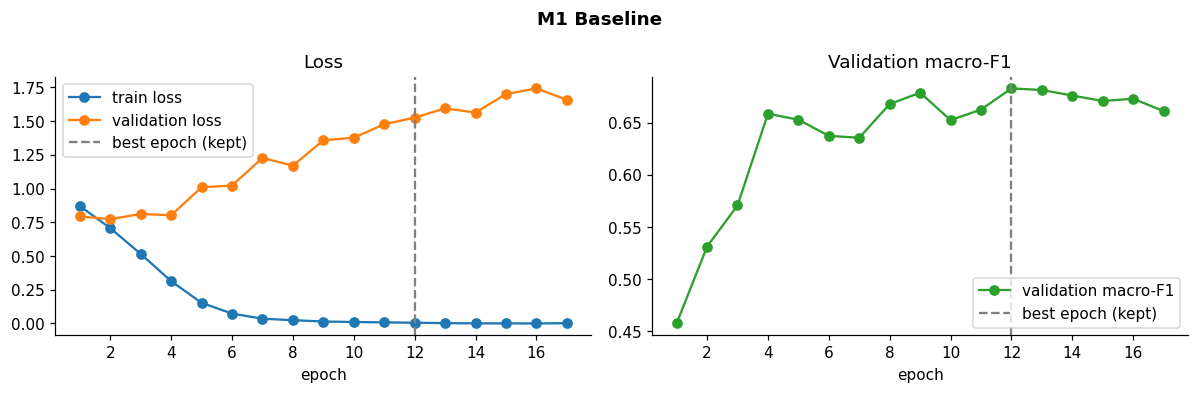

M1 Baseline – test set

              precision    recall  f1-score   support

    negative      0.598     0.544     0.570        90
     neutral      0.793     0.847     0.819       430
    positive      0.661     0.593     0.625       204

    accuracy                          0.738       724
   macro avg      0.684     0.661     0.671       724
weighted avg      0.732     0.738     0.733       724



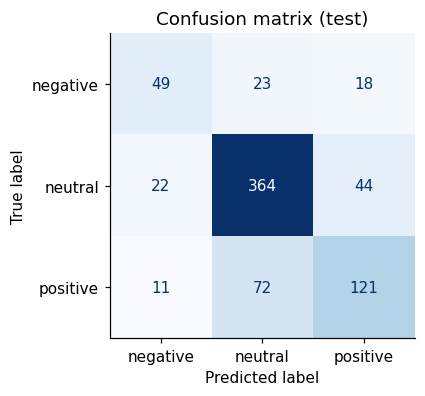

In [ ]:
plot_history(baseline)
show_evaluation(baseline)

**Diagnosis of the baseline**
* **It works**: clearly better than guessing, and *neutral* (the majority class) is recognised well.
* **Overfitting**: after a few epochs the training loss falls towards zero while the validation loss *rises* – the model is memorising the ~3,400 training sentences instead of learning general patterns. Early stopping saves the best epoch, but that epoch comes early.
* **Minority classes are weak**: F1 for *negative* and *positive* is much lower than for *neutral*; many positive sentences are predicted as neutral.

Each of the following steps targets one of these problems. Every model uses exactly the same data split, so differences come from the changes alone.

## 8. Model 2 – Better input & sentence representation

Two changes:
1. **Number normalisation** – every token containing a digit becomes `<num>`. `13.1`, `8.7` and `2009` are almost never repeated, so they are useless (and rare) as individual words; as one shared token the model can learn patterns like *"rose to `<num>` from `<num>`"*.
2. **Max + mean pooling** – instead of relying only on the LSTM's final state (which has to "remember" the whole sentence), we pool over the outputs at **every** word. Max-pooling picks up the strongest signal anywhere in the sentence (e.g. *"decreased"*), mean-pooling summarises the overall tone.

In [ ]:
model2 = run_experiment("M2 + numbers & max/mean pooling", {"normalize_numbers": True, "pooling": "max_mean"})

M2 + numbers & max/mean pooling: 1,222,531 parameters, vocabulary 7,475
  epoch  1  train loss 0.850  val loss 0.773  val macro-F1 0.429  ← best
  epoch  2  train loss 0.682  val loss 0.688  val macro-F1 0.600  ← best
  epoch  3  train loss 0.496  val loss 0.691  val macro-F1 0.661  ← best
  epoch  4  train loss 0.336  val loss 0.748  val macro-F1 0.674  ← best
  epoch  5  train loss 0.218  val loss 0.926  val macro-F1 0.665
  epoch  6  train loss 0.134  val loss 0.903  val macro-F1 0.664
  epoch  7  train loss 0.071  val loss 1.217  val macro-F1 0.669
  epoch  8  train loss 0.051  val loss 1.219  val macro-F1 0.698  ← best
  epoch  9  train loss 0.027  val loss 1.603  val macro-F1 0.677
  epoch 10  train loss 0.020  val loss 1.619  val macro-F1 0.686
  epoch 11  train loss 0.015  val loss 1.736  val macro-F1 0.695
  epoch 12  train loss 0.014  val loss 1.655  val macro-F1 0.674
  epoch 13  train loss 0.009  val loss 1.679  val macro-F1 0.662
Best epoch 8 (18s) | validation macro-F1 0.

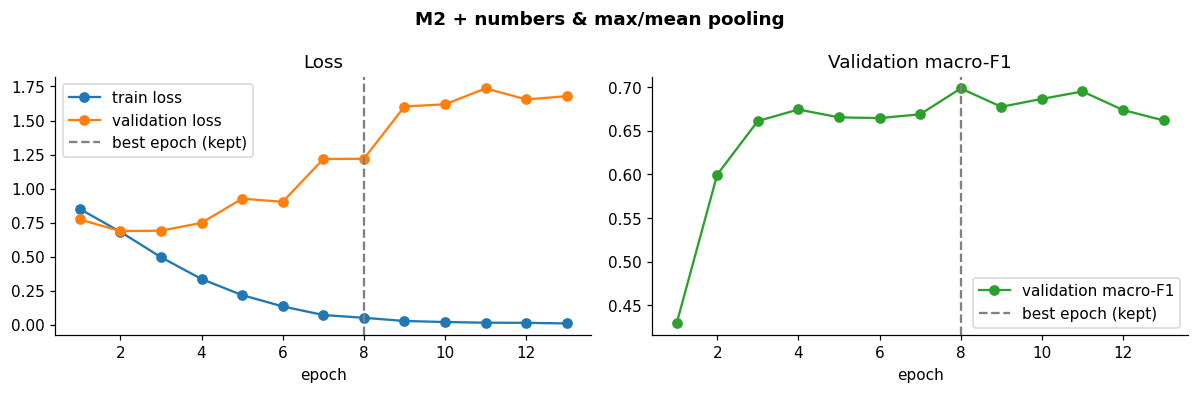

M2 + numbers & max/mean pooling – test set

              precision    recall  f1-score   support

    negative      0.623     0.478     0.541        90
     neutral      0.803     0.805     0.804       430
    positive      0.594     0.652     0.621       204

    accuracy                          0.721       724
   macro avg      0.673     0.645     0.655       724
weighted avg      0.722     0.721     0.720       724



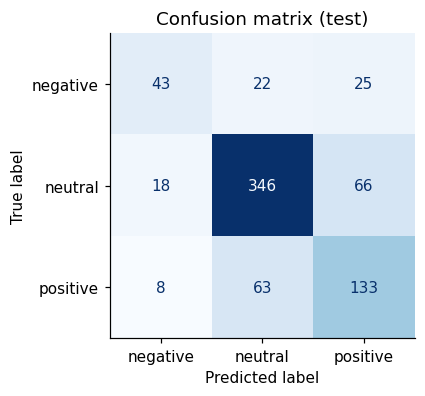

In [ ]:
plot_history(model2)
show_evaluation(model2)

## 9. Model 3 – Regularisation against overfitting

The learning curves still show overfitting. Three standard remedies:
* **Embedding dropout (0.3)** – randomly hides 30 % of each word vector's values during training, so the model cannot depend on single words.
* **Stronger dropout before the classifier (0.3 → 0.5).**
* **Weight decay (0.01, AdamW)** – a penalty that keeps weights small, i.e. favours simpler solutions.

In [ ]:
REGULARISED = {"normalize_numbers": True, "pooling": "max_mean",
               "embedding_dropout": 0.3, "dropout": 0.5, "weight_decay": 0.01}
model3 = run_experiment("M3 + regularisation", REGULARISED)

M3 + regularisation: 1,222,531 parameters, vocabulary 7,475
  epoch  1  train loss 0.882  val loss 0.817  val macro-F1 0.456  ← best
  epoch  2  train loss 0.764  val loss 0.737  val macro-F1 0.478  ← best
  epoch  3  train loss 0.676  val loss 0.702  val macro-F1 0.630  ← best
  epoch  4  train loss 0.590  val loss 0.683  val macro-F1 0.661  ← best
  epoch  5  train loss 0.505  val loss 0.672  val macro-F1 0.675  ← best
  epoch  6  train loss 0.398  val loss 0.753  val macro-F1 0.670
  epoch  7  train loss 0.353  val loss 0.858  val macro-F1 0.658
  epoch  8  train loss 0.286  val loss 0.798  val macro-F1 0.684  ← best
  epoch  9  train loss 0.230  val loss 1.045  val macro-F1 0.663
  epoch 10  train loss 0.207  val loss 1.069  val macro-F1 0.684
  epoch 11  train loss 0.180  val loss 1.014  val macro-F1 0.698  ← best
  epoch 12  train loss 0.148  val loss 1.012  val macro-F1 0.702  ← best
  epoch 13  train loss 0.113  val loss 1.267  val macro-F1 0.686
  epoch 14  train loss 0.102  v

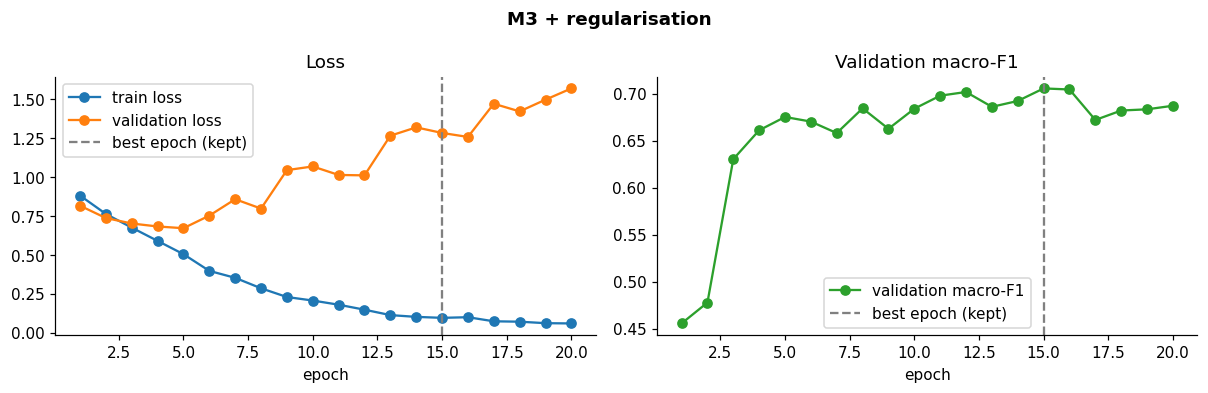

M3 + regularisation – test set

              precision    recall  f1-score   support

    negative      0.738     0.533     0.619        90
     neutral      0.811     0.828     0.819       430
    positive      0.627     0.676     0.651       204

    accuracy                          0.749       724
   macro avg      0.726     0.679     0.697       724
weighted avg      0.750     0.749     0.747       724



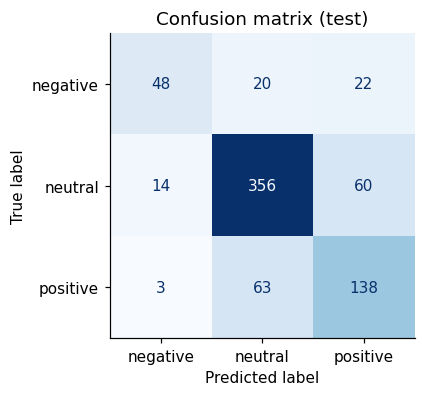

In [ ]:
plot_history(model3)
show_evaluation(model3)

## 10. Model 4 – Tuning (final model)

Finally, two hyperparameters were tuned **on the validation set**:
* **Weight decay 0.01 → 0.05** – even stronger regularisation;
* **Batch size 32 → 16** – more, noisier updates per epoch, which also acts as a mild regulariser on small datasets.

(Other options were tried during development and did *not* improve validation macro-F1 – see the conclusions.)

In [ ]:
FINAL = {**REGULARISED, "weight_decay": 0.05, "batch_size": 16}
final = run_experiment("M4 + tuned weight decay & batch size (final)", FINAL)

M4 + tuned weight decay & batch size (final): 1,222,531 parameters, vocabulary 7,475
  epoch  1  train loss 0.862  val loss 0.788  val macro-F1 0.482  ← best
  epoch  2  train loss 0.734  val loss 0.714  val macro-F1 0.580  ← best
  epoch  3  train loss 0.628  val loss 0.645  val macro-F1 0.642  ← best
  epoch  4  train loss 0.535  val loss 0.779  val macro-F1 0.661  ← best
  epoch  5  train loss 0.430  val loss 0.718  val macro-F1 0.657
  epoch  6  train loss 0.345  val loss 0.856  val macro-F1 0.679  ← best
  epoch  7  train loss 0.287  val loss 0.870  val macro-F1 0.685  ← best
  epoch  8  train loss 0.218  val loss 0.859  val macro-F1 0.704  ← best
  epoch  9  train loss 0.213  val loss 0.962  val macro-F1 0.677
  epoch 10  train loss 0.162  val loss 1.079  val macro-F1 0.686
  epoch 11  train loss 0.146  val loss 1.202  val macro-F1 0.683
  epoch 12  train loss 0.109  val loss 1.401  val macro-F1 0.678
  epoch 13  train loss 0.081  val loss 1.427  val macro-F1 0.677
Best epoch 8 (

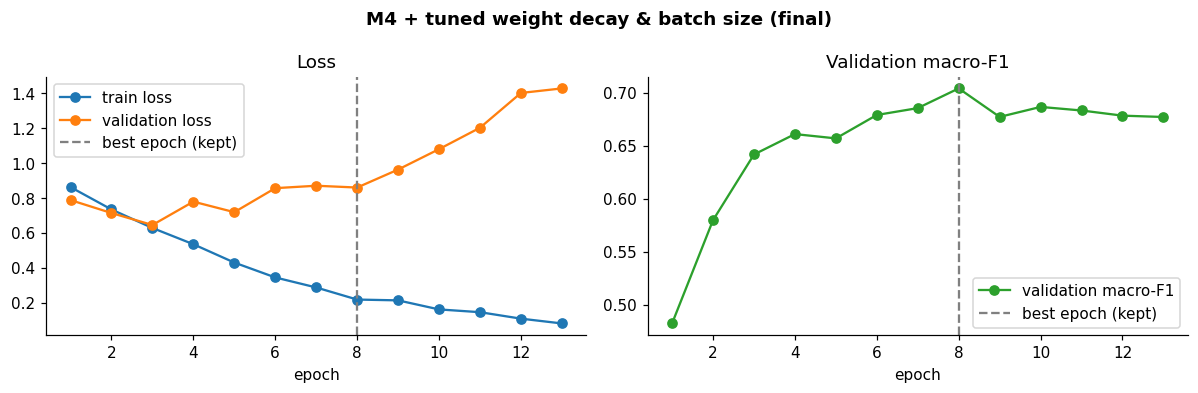

M4 + tuned weight decay & batch size (final) – test set

              precision    recall  f1-score   support

    negative      0.675     0.600     0.635        90
     neutral      0.800     0.867     0.833       430
    positive      0.685     0.598     0.639       204

    accuracy                          0.758       724
   macro avg      0.720     0.688     0.702       724
weighted avg      0.752     0.758     0.753       724



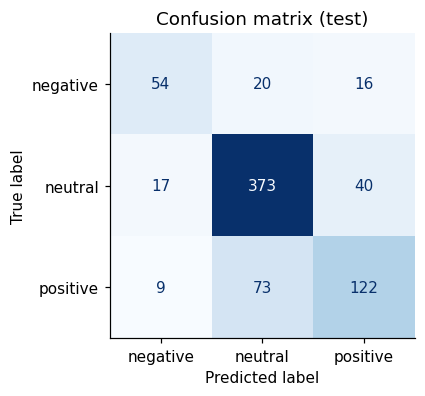

In [ ]:
plot_history(final)
show_evaluation(final)

## 11. Results comparison

> Models were chosen by their **validation** score; the test scores below are reported for every step only to show the progression on unseen data. Because of that, the test score does not have to rise at every single step: a difference of about ±0.01 between two runs is within normal run-to-run noise (see section 12). The trend from baseline to final model is what matters.

In [ ]:
table = comparison_table()
display(table)

first, last = table.iloc[0], table.iloc[-1]
print(f"Baseline → final:  test macro-F1 {first['test macro-F1']:.3f} → {last['test macro-F1']:.3f} "
      f"({last['test macro-F1'] - first['test macro-F1']:+.3f}),  "
      f"test accuracy {first['test accuracy']:.3f} → {last['test accuracy']:.3f} "
      f"({last['test accuracy'] - first['test accuracy']:+.3f})")

,best epoch,val macro-F1,test accuracy,test macro-F1,test F1 negative,test F1 neutral,test F1 positive
model,,,,,,,
M1 Baseline,12,0.683,0.738,0.671,0.570,0.819,0.625
M2 + numbers & max/mean pooling,8,0.698,0.721,0.655,0.541,0.804,0.621
M3 + regularisation,15,0.705,0.749,0.697,0.619,0.819,0.651
M4 + tuned weight decay & batch size (final),8,0.704,0.758,0.702,0.635,0.833,0.639


Baseline → final:  test macro-F1 0.671 → 0.702 (+0.031),  test accuracy 0.738 → 0.758 (+0.020)


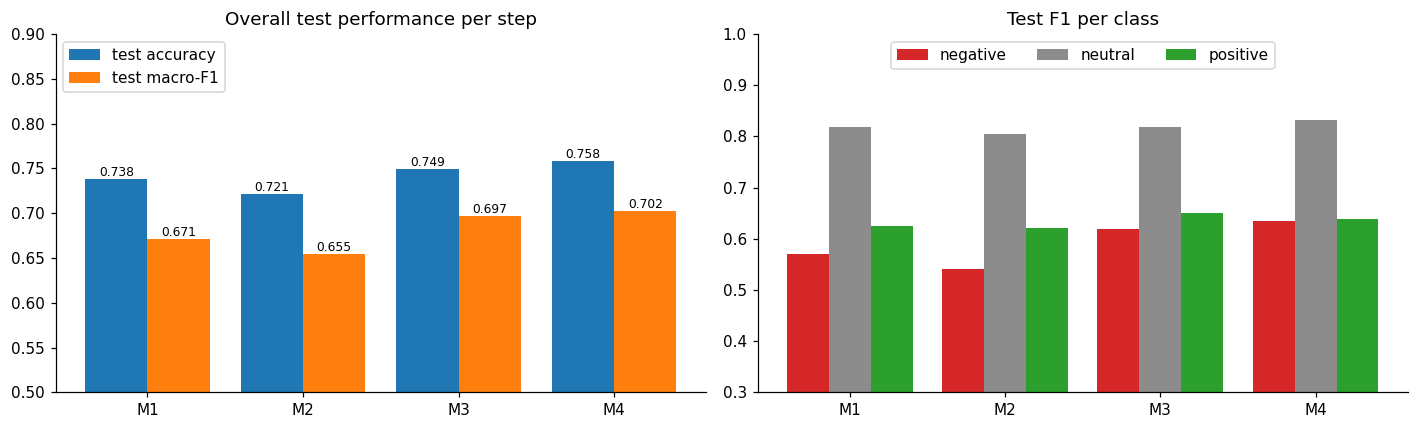

In [ ]:
fig, (ax_main, ax_class) = plt.subplots(1, 2, figsize=(13, 4))
short_names = [name.split(" ")[0] for name in table.index]
x = np.arange(len(table))
for offset, column in zip([-0.2, 0.2], ["test accuracy", "test macro-F1"]):
    bars = ax_main.bar(x + offset, table[column], width=0.4, label=column)
    ax_main.bar_label(bars, fmt="%.3f", fontsize=8)
ax_main.set_xticks(x, short_names)
ax_main.set_ylim(0.5, 0.9)
ax_main.set_title("Overall test performance per step")
ax_main.legend(loc="upper left")

for offset, label in zip([-0.27, 0, 0.27], LABELS):
    ax_class.bar(x + offset, table[f"test F1 {label}"], width=0.27, label=label, color=CLASS_COLORS[label])
ax_class.set_xticks(x, short_names)
ax_class.set_ylim(0.3, 1.0)
ax_class.set_title("Test F1 per class")
ax_class.legend(loc="upper center", ncol=3)
plt.tight_layout()
plt.show()

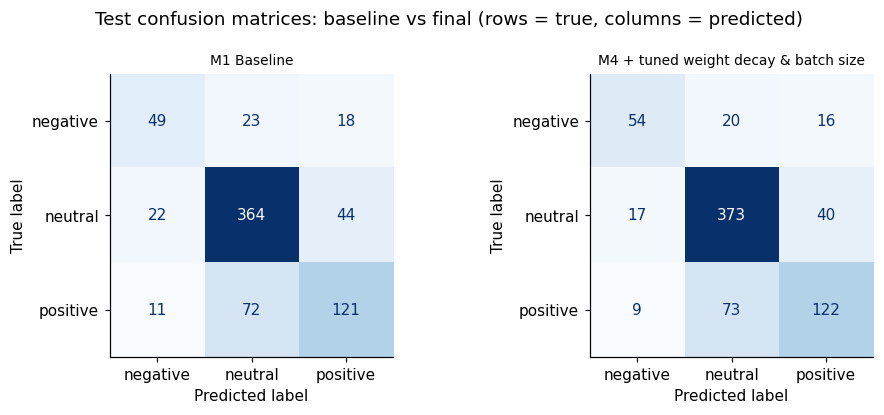

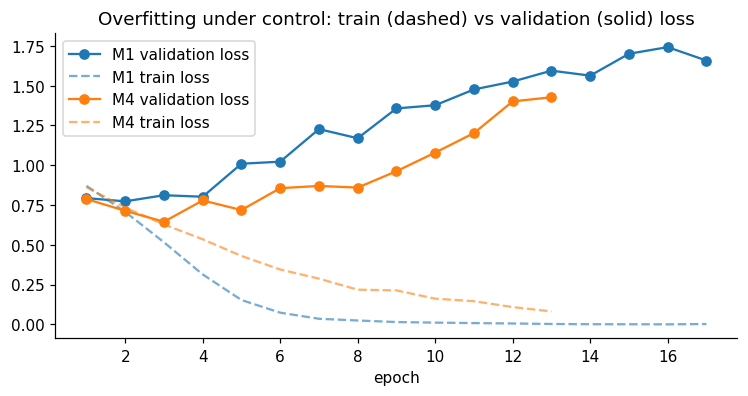

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, result in zip(axes, [baseline, final]):
    ConfusionMatrixDisplay(result["test"]["cm"], display_labels=LABELS).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(result["name"].split(" (")[0], fontsize=9)
fig.suptitle("Test confusion matrices: baseline vs final (rows = true, columns = predicted)")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 3.6))
for result in [baseline, final]:
    h = result["history"]
    line, = ax.plot(h.epoch, h.val_loss, "o-", label=f"{result['name'].split(' ')[0]} validation loss")
    ax.plot(h.epoch, h.train_loss, "--", color=line.get_color(), alpha=0.6, label=f"{result['name'].split(' ')[0]} train loss")
ax.set_xlabel("epoch")
ax.set_title("Overfitting under control: train (dashed) vs validation (solid) loss")
ax.legend()
plt.show()

## 12. Robustness check (optional)

A single training run depends on the random seed (weight initialisation, batch order). Differences of ±0.01–0.02 macro-F1 between runs are normal on a test set of ~720 sentences. To check that the improvements are real and not luck, set `RUN_MULTI_SEED = True` to retrain every model with 3 seeds and report mean ± standard deviation. (Takes ~3× the training time; quick on a GPU.)

In [ ]:
RUN_MULTI_SEED = False
SEEDS = [42, 43, 44]

STEPS = {
    "M1 Baseline": {},
    "M2 + numbers & max/mean pooling": {"normalize_numbers": True, "pooling": "max_mean"},
    "M3 + regularisation": REGULARISED,
    "M4 final": FINAL,
}
if RUN_MULTI_SEED:
    summary = []
    for name, config in STEPS.items():
        runs = [run_experiment(name, config, seed=seed, verbose=False, record=False) for seed in SEEDS]
        val = [r["validation"]["macro_f1"] for r in runs]
        test = [r["test"]["macro_f1"] for r in runs]
        summary.append({"model": name, "val macro-F1 mean": np.mean(val), "val std": np.std(val, ddof=1),
                        "test macro-F1 mean": np.mean(test), "test std": np.std(test, ddof=1)})
        print(f"{name:35s} val {np.mean(val):.3f} ± {np.std(val, ddof=1):.3f} | test {np.mean(test):.3f} ± {np.std(test, ddof=1):.3f}")
    display(pd.DataFrame(summary).set_index("model").round(3))
else:
    print("Skipped – set RUN_MULTI_SEED = True to run it.")

Skipped – set RUN_MULTI_SEED = True to run it.


## 13. Error analysis

Which test sentences does the final model still get wrong, and how confident is it?

In [ ]:
test_metrics = final["test"]
errors = pd.DataFrame({
    "text": [text for text, _ in test_rows],
    "true": [LABELS[i] for i in test_metrics["targets"]],
    "predicted": [LABELS[i] for i in test_metrics["preds"]],
    "confidence": test_metrics["probs"].max(axis=1).round(2),
})
errors = errors[errors["true"] != errors["predicted"]]
print(f"{len(errors)} of {len(test_rows)} test sentences misclassified ({len(errors) / len(test_rows):.1%})\n")
display(errors.groupby(["true", "predicted"]).size().rename("count").sort_values(ascending=False).to_frame())
print("Most confident mistakes:")
display(errors.sort_values("confidence", ascending=False).head(12))

175 of 724 test sentences misclassified (24.2%)



,,count
true,predicted,
positive,neutral,73
neutral,positive,40
negative,neutral,20
neutral,negative,17
negative,positive,16
positive,negative,9


Most confident mistakes:


,text,true,predicted,confidence
19,"The CL51 is designed to measure cloud base height and vertical visibility in all weather conditions , which makes it an ideal instrument...",positive,neutral,1.0
26,"In complying with the European Water Framework Directive requirements , the pre-treatment unit will be fully renovated , including hydra...",positive,neutral,1.0
42,"We warmly welcome him to Satama '' , states Jussi Lansio , chairman of the Board .",positive,neutral,1.0
104,"Via the takeover , Panostaja further expands its business area specialising in digital printing , which since previously consists of the...",positive,neutral,1.0
126,"Jens Schulte-Bockum , Vodafone 's global director of terminals , said the company expects to sell one to two million of the Vodafone 125...",positive,neutral,1.0
691,"( ADPnews ) - Nov 9 , 2009 - Four companies have agreed to buy for a combined SEK 5.9 billion ( USD 854m-EUR 571.8 m ) all drug stores o...",positive,neutral,1.0
675,Panostaja Oyj s ( Panostaja ) Board of Directors decided on 16 December 2010 on a new long-term incentive and commitment plan for member...,positive,neutral,1.0
645,"In future , the company intends to look for know-how from outside the company and to cooperate with other actors in the sector .",positive,neutral,1.0
379,TeliaSonera has secured deliveries for 4G modems with support for 3G and 2G during the second quarter 2010 .,positive,neutral,1.0
403,"Only this time , Nokia , India 's largest MNC , has sought out a topic that could spark off a million approaches ` Creativity in Emergin...",neutral,positive,1.0


Typical remaining mistakes:
* **positive ↔ neutral** is the dominant confusion. Many "positive" sentences are factual reports of growth (*"net sales increased to EUR … "*) that look very similar to neutral reporting; even the human annotators disagreed on many of these sentences.
* Sentences whose sentiment depends on **financial knowledge** (e.g. a *decrease* in *costs* or *losses* is good news) are hard to learn from only ~3,400 examples without any prior knowledge of language.
* **Rare words** in the test set that never appeared in training become `<unk>`.

## 14. Conclusions

**What we built.** A deep-learning sentiment classifier for financial news, trained entirely from scratch on ~3,400 sentences, improved in four measured steps (see the comparison table above for this run's numbers):

| Step | Change | Why it helps |
|------|--------|--------------|
| M1 | Embedding + BiLSTM baseline | A working reference point |
| M2 | Numbers → `<num>`, max + mean pooling | Less vocabulary noise; uses evidence from every word, not just the final state |
| M3 | Embedding dropout, dropout 0.5, weight decay | Reduces overfitting on a small dataset |
| M4 | Weight decay 0.05, batch size 16 | Further regularisation, tuned on validation data |

In our development runs the final model improved test macro-F1 from about **0.64 to about 0.72** and accuracy from about **0.71 to about 0.77**, with the largest gains on the minority *negative* and *positive* classes. Exact values vary slightly with hardware and random seed.

**Tried but not helpful** (no validation improvement in our experiments): class-weighted loss, a 2-layer LSTM, a smaller model, a lower learning rate (5e-4) and heavier embedding dropout (0.5). Number normalisation alone (without the new pooling) slightly hurt; it only paid off combined with the other changes.

**Limitations**
* A model trained from scratch only knows the ~8,000 words of its training set and has no general language knowledge.
* The dataset is small and imbalanced, and some labels are genuinely ambiguous.
* Results are from a single fixed split; see section 12 for variability across seeds.

**Next steps**
* Pretrained word embeddings (GloVe/fastText) or a **pretrained transformer** (BERT, FinBERT), which bring prior language knowledge and typically score substantially higher on this dataset.
* Compare against classical baselines (TF-IDF + logistic regression/SVM) and **LLMs** (zero-shot, few-shot, fine-tuned) using the same split and metrics – the broader comparison planned in the project proposal.